# Adam Optimiser: What It Does Well, and What It Doesn't

Adam (Adaptive Moment Estimation) combines two ideas: **Momentum** (a moving average of the gradient) and **RMSProp** (a per-parameter rescaling by a moving average of the squared gradient).

This notebook implements GD, Momentum, AdaGrad, RMSProp and Adam from scratch in NumPy and compares them on three 2-D quadratic loss surfaces. The goal is to see **where Adam helps, where it doesn't, and why**.


| Experiment | Question |
|---|---|
| 1 | On the easy problem, who converges fastest at one shared learning rate? |
| 2 | How sensitive is each optimiser to the learning rate $\eta$? |
| 3 | What happens on badly scaled (κ = 1000) and rotated valleys? |
| 4 | Why does Adam need bias correction? |

**Notations**: parameters $w$, loss $L(w)$, gradient $g_t=\nabla L(w_{t-1})$, learning rate $\eta$, Hessian $H$, condition number $\kappa=\lambda_{\max}/\lambda_{\min}$.

## The Adam Update

Adam keeps two exponential moving averages, per parameter:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\,g_t \qquad\text{(first moment, the Momentum idea)}$$

$$v_t = \beta_2 v_{t-1} + (1-\beta_2)\,g_t^{2} \qquad\text{(second moment, the RMSProp idea)}$$

Both start at $0$, so early values are biased towards zero. Adam divides this bias out:

$$\hat m_t = \frac{m_t}{1-\beta_1^{\,t}}, \qquad \hat v_t = \frac{v_t}{1-\beta_2^{\,t}}$$

and then updates

$$w_t = w_{t-1} - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$

Defaults: $\beta_1=0.9$, $\beta_2=0.999$, $\epsilon=10^{-8}$.

**Key consequence:** If a coordinate's gradient is consistent, $\hat m_t/\sqrt{\hat v_t}\approx\pm1$, so Adam's step in that coordinate has size roughly $\eta$ *whatever the gradient's scale*. This is a per-coordinate rescaling, i.e. a **diagonal preconditioner**. It should help when different coordinates have very different curvature, and it cannot help when the difficulty is not aligned with the coordinate axes. Experiments 2 and 3 test exactly that.

## Test Problems

All three are quadratics $L(w)=\tfrac12 w^\top H w$, so the minimum is at $(0,0)$ and the Hessian is known exactly. The condition number $\kappa=\lambda_{\max}/\lambda_{\min}$ measures how elongated the valley is.

| Problem | $L(w)$ | Hessian eigenvalues | $\kappa$ | Valley |
|---|---|---|---|---|
| **A** | $w_1^2+10\,w_2^2$ | 2, 20 | **10** | aligned with the axes |
| **B** | $w_1^2+1000\,w_2^2$ | 2, 2000 | **1000** | aligned with the axes |
| **C** | same curvatures as B | 2, 2000 | **1000** | **rotated by 30°** |

A is the function from the original notebook. Its Hessian is $\mathrm{diag}(2,20)$, so $\kappa=20/2=10$. That is only moderately ill-conditioned. B makes the scale mismatch severe, and C keeps the same curvatures as B but rotates the valley so that the coordinate axes no longer line up with it.

For plain gradient descent on a quadratic, the stable range is $\eta<2/\lambda_{\max}$ (0.1 for A, 0.001 for B and C).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
def make_quadratic(eigs, theta=0.0, name=""):
    """L(w) = 0.5 * w^T H w  with  H = R diag(eigs) R^T.
    theta = 0 gives an axis-aligned Hessian; theta != 0 rotates the valley."""
    c, s = np.cos(theta), np.sin(theta)
    R = np.array([[c, -s], [s, c]])
    H = R @ np.diag(eigs) @ R.T
    return {
        "name": name,
        "L": lambda w: 0.5 * w @ H @ w,
        "grad": lambda w: H @ w,
        "H": H,
        "kappa": max(eigs) / min(eigs),
        "lam_max": max(eigs),
    }

# A: L = w1^2 + 10 w2^2          ->  H = diag(2, 20),    kappa = 10
prob_A = make_quadratic([2, 20],   theta=0.0,       name="A: axis-aligned, kappa = 10")
# B: L = w1^2 + 1000 w2^2        ->  H = diag(2, 2000),  kappa = 1000
prob_B = make_quadratic([2, 2000], theta=0.0,       name="B: axis-aligned, kappa = 1000")
# C: same curvatures as B, valley rotated by 30 degrees
prob_C = make_quadratic([2, 2000], theta=np.pi / 6, name="C: rotated 30 deg, kappa = 1000")

PROBLEMS = (prob_A, prob_B, prob_C)
w0 = np.array([-2.0, 0.8])          # common starting point

for p in PROBLEMS:
    ev = np.linalg.eigvalsh(p["H"])
    print(f"{p['name']:38s} eigenvalues = {np.round(ev, 2)},  kappa = {p['kappa']:.0f},  "
          f"GD stability limit 2/lambda_max = {2 / p['lam_max']:.4f}")

A: axis-aligned, kappa = 10            eigenvalues = [ 2. 20.],  kappa = 10,  GD stability limit 2/lambda_max = 0.1000
B: axis-aligned, kappa = 1000          eigenvalues = [   2. 2000.],  kappa = 1000,  GD stability limit 2/lambda_max = 0.0010
C: rotated 30 deg, kappa = 1000        eigenvalues = [   2. 2000.],  kappa = 1000,  GD stability limit 2/lambda_max = 0.0010


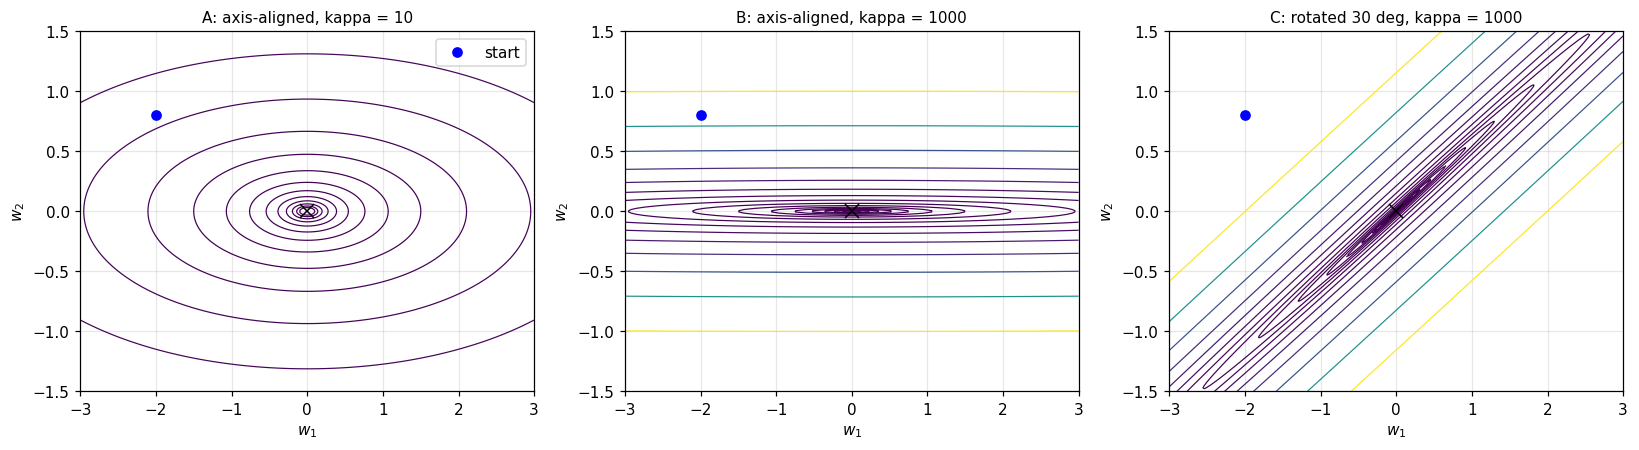

In [3]:
def draw_contours(ax, prob, xlim=(-3, 3), ylim=(-1.5, 1.5), n=300):
    xs = np.linspace(*xlim, n)
    ys = np.linspace(*ylim, n)
    X, Y = np.meshgrid(xs, ys)
    Z = np.array([[prob["L"](np.array([a, b])) for a in xs] for b in ys])
    ax.contour(X, Y, Z, levels=np.logspace(-2, 3, 18), cmap="viridis", linewidths=0.8)
    ax.plot(0, 0, "kx", ms=9)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel("$w_1$"); ax.set_ylabel("$w_2$")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, p in zip(axes, PROBLEMS):
    draw_contours(ax, p)
    ax.plot(*w0, "bo", label="start")
    ax.set_title(p["name"], fontsize=10)
axes[0].legend()
plt.tight_layout()
plt.show()

## The Optimisers

Each function takes the gradient, a start point, a learning rate and an iteration count, and returns the whole path. The update rules:

| Optimiser | Update |
|---|---|
| GD | $w \leftarrow w-\eta g$ |
| Momentum | $V\leftarrow\beta V+\eta g,\quad w\leftarrow w-V$ |
| AdaGrad | $G\leftarrow G+g^2,\quad w\leftarrow w-\eta\,g/(\sqrt G+\epsilon)$ |
| RMSProp | $G\leftarrow\beta G+(1-\beta)g^2,\quad w\leftarrow w-\eta\,g/(\sqrt G+\epsilon)$ |
| Adam | as in Section 1 |

(Operations on vectors are element-wise. Momentum and RMSProp use $\beta=0.9$.)

In [4]:
# All optimisers share one interface and return the full path of parameters.

def gradient_descent(grad, w0, lr, n_iter):
    w = np.array(w0, float)
    path = [w.copy()]
    for _ in range(n_iter):
        w = w - lr * grad(w)
        path.append(w.copy())
    return np.array(path)


def momentum(grad, w0, lr, n_iter, beta=0.9):
    w = np.array(w0, float)
    V = np.zeros_like(w)
    path = [w.copy()]
    for _ in range(n_iter):
        V = beta * V + lr * grad(w)           # velocity: decaying memory of past gradients
        w = w - V
        path.append(w.copy())
    return np.array(path)


def adagrad(grad, w0, lr, n_iter, eps=1e-8):
    w = np.array(w0, float)
    G = np.zeros_like(w)                      # running SUM of squared gradients
    path = [w.copy()]
    for _ in range(n_iter):
        g = grad(w)
        G = G + g**2
        w = w - lr * g / (np.sqrt(G) + eps)
        path.append(w.copy())
    return np.array(path)


def rmsprop(grad, w0, lr, n_iter, beta=0.9, eps=1e-8):
    w = np.array(w0, float)
    G = np.zeros_like(w)                      # exponential MOVING AVERAGE of squared gradients
    path = [w.copy()]
    for _ in range(n_iter):
        g = grad(w)
        G = beta * G + (1 - beta) * g**2
        w = w - lr * g / (np.sqrt(G) + eps)
        path.append(w.copy())
    return np.array(path)


def adam(grad, w0, lr, n_iter, beta1=0.9, beta2=0.999, eps=1e-8):
    w = np.array(w0, float)
    m = np.zeros_like(w)                      # 1st moment: moving average of g    (the Momentum idea)
    v = np.zeros_like(w)                      # 2nd moment: moving average of g^2  (the RMSProp idea)
    path = [w.copy()]
    for t in range(1, n_iter + 1):
        g = grad(w)
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * g**2
        m_hat = m / (1 - beta1**t)            # bias correction: m and v start at 0
        v_hat = v / (1 - beta2**t)
        w = w - lr * m_hat / (np.sqrt(v_hat) + eps)
        path.append(w.copy())
    return np.array(path)


OPTIMISERS = {
    "GD":       (gradient_descent, "tab:purple"),
    "Momentum": (momentum,         "tab:orange"),
    "AdaGrad":  (adagrad,          "tab:brown"),
    "RMSProp":  (rmsprop,          "tab:cyan"),
    "Adam":     (adam,             "tab:red"),
}


def run(name, prob, lr, n_iter, start=w0):
    """Run one optimiser. Returns (path, loss history); diverged runs give nan losses."""
    fn = OPTIMISERS[name][0]
    with np.errstate(all="ignore"):
        path = fn(prob["grad"], start, lr, n_iter)
        loss = np.array([prob["L"](p) for p in path])
    loss[~np.isfinite(loss) | (loss > 1e12)] = np.nan
    return path, loss

## Experiment 1: One Shared Learning Rate on Problem A

Everyone gets $\eta=0.03$ for 100 iterations. (I avoid $\eta=0.05$ for the main run because $0.05=1/\lambda_{\max}$ is a special value for GD on this problem: it removes the $w_2$ error in a single step, which flatters GD.)

GD        final L = 1.689e-05
Momentum  final L = 2.555e-04
AdaGrad   final L = 3.258e+00
RMSProp   final L = 4.084e-08
Adam      final L = 9.270e-03


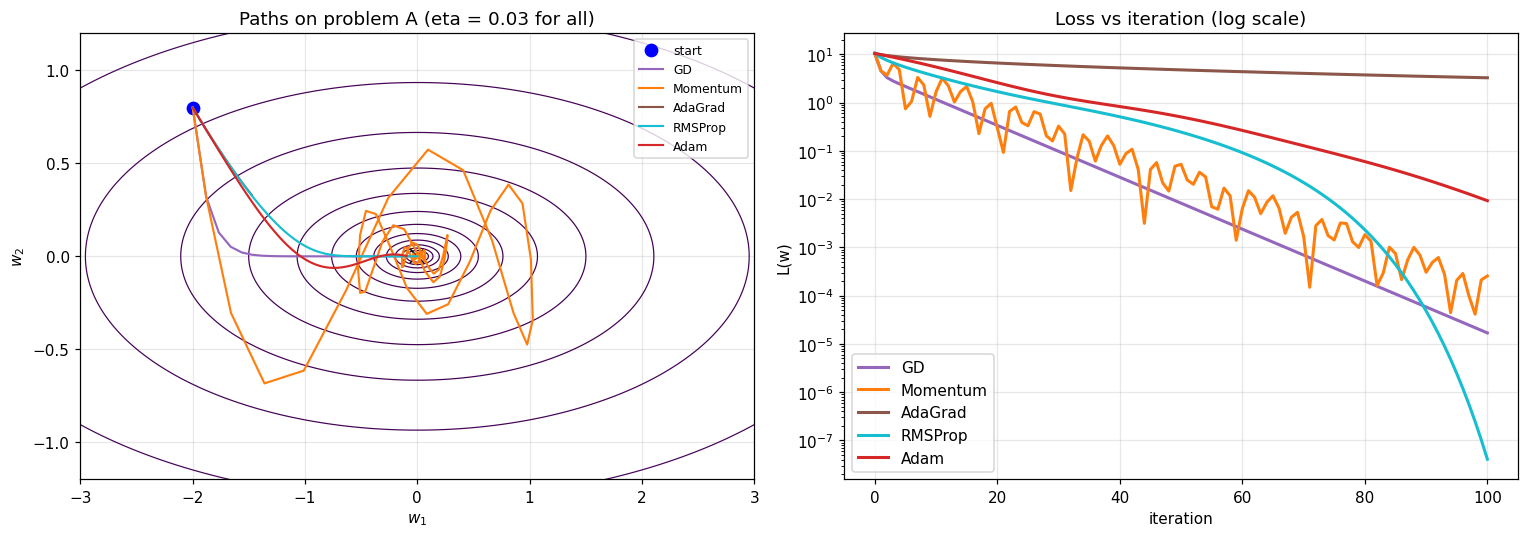


Same run at eta = 0.05:
GD        final L = 2.822e-09
Momentum  final L = 6.758e-05
AdaGrad   final L = 1.540e+00
RMSProp   final L = 1.072e-05
Adam      final L = 2.814e-04


In [5]:
# Experiment 1: problem A, ONE shared learning rate, 100 iterations.
LR = 0.03
N = 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
draw_contours(axes[0], prob_A, xlim=(-3, 3), ylim=(-1.2, 1.2))
axes[0].plot(*w0, "bo", ms=8, label="start")

for name, (_, color) in OPTIMISERS.items():
    path, loss = run(name, prob_A, LR, N)
    axes[0].plot(path[:, 0], path[:, 1], "-", color=color, lw=1.4, label=name)
    axes[1].semilogy(loss, color=color, lw=2, label=name)
    print(f"{name:9s} final L = {loss[-1]:.3e}")

axes[0].set_title(f"Paths on problem A (eta = {LR} for all)")
axes[0].legend(fontsize=8)
axes[1].set_title("Loss vs iteration (log scale)")
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("L(w)"); axes[1].legend()
plt.tight_layout(); plt.show()

# The ranking depends on the learning rate. Same experiment at eta = 0.05 (= 1 / lambda_max):
print("\nSame run at eta = 0.05:")
for name in OPTIMISERS:
    print(f"{name:9s} final L = {run(name, prob_A, 0.05, N)[1][-1]:.3e}")

**What to take from this**

- Adam is **not** the fastest here. RMSProp and GD are far ahead, and Adam finishes with a loss of about $10^{-2}$.
- Adam's steps are about $\eta$ per coordinate, so reaching $w_1=-2$ from the start takes on the order of $2/\eta\approx 70$ iterations no matter how gentle the slope is. On an easy, deterministic problem that is a handicap.
- AdaGrad barely moves at this $\eta$: its accumulated sum $G$ keeps growing, which shrinks the effective step $\eta/\sqrt G$ (we will see it work at larger $\eta$ in Experiment 2).
- Momentum's loss curve oscillates, which is the overshoot you expect from velocity.
- The ranking changes with $\eta$: at $\eta=0.05$ (second printout) GD jumps to first place. **A single-$\eta$ ranking therefore says little about the algorithms**, which is why Experiment 2 sweeps $\eta$.

## Experiment 2: Learning Rate Sensitivity

For each optimiser and each of 25 learning rates between $10^{-4}$ and $1$ (log-spaced), run 200 iterations and record the final loss. A curve that stays low across a wide range of $\eta$ means the optimiser is forgiving; a narrow dip means it must be tuned carefully. Points that are missing (or, for GD and Momentum, curves that stop) are runs that diverged; values below $10^{-16}$ fall off the bottom of the plot.

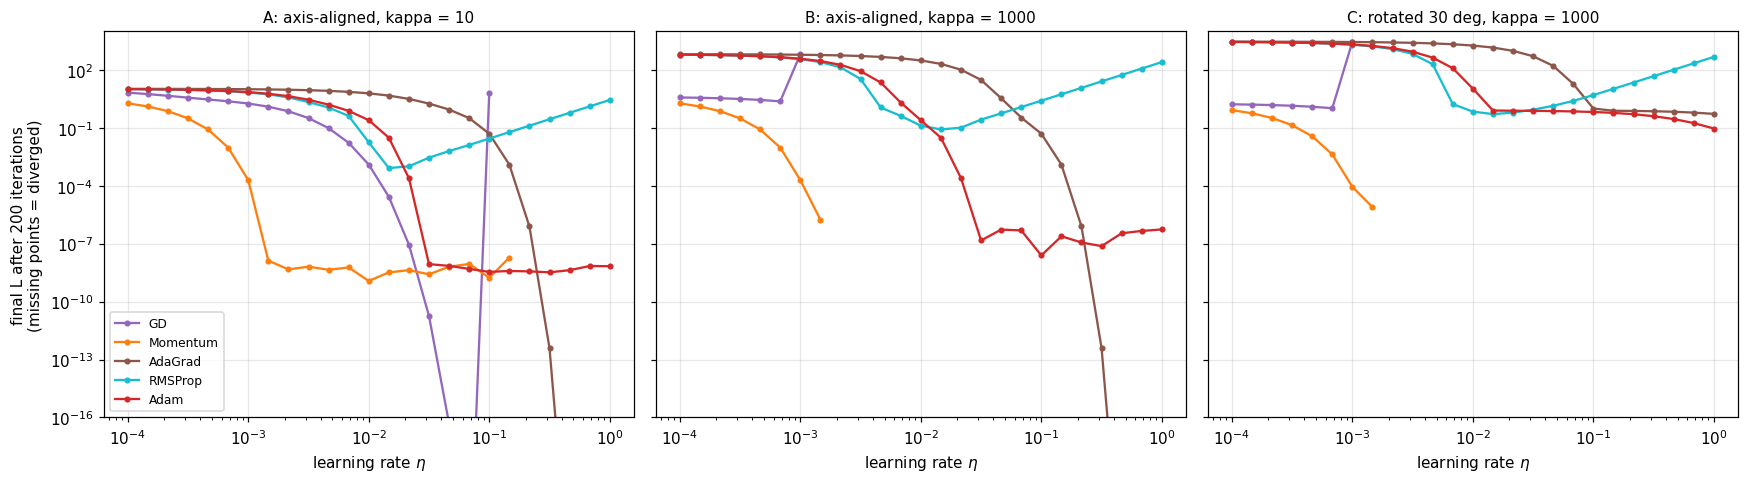

In [6]:
# Experiment 2: learning-rate sweep. For every (optimiser, eta) run 200 iterations and record the final loss.
lrs = np.logspace(-4, 0, 25)
N_SWEEP = 200

def lr_sweep(prob):
    return {name: np.array([run(name, prob, lr, N_SWEEP)[1][-1] for lr in lrs])
            for name in OPTIMISERS}

sweeps = {p["name"]: lr_sweep(p) for p in PROBLEMS}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, p in zip(axes, PROBLEMS):
    for name, (_, color) in OPTIMISERS.items():
        ax.loglog(lrs, sweeps[p["name"]][name], "-o", ms=3, color=color, label=name)
    ax.set_title(p["name"], fontsize=10)
    ax.set_xlabel("learning rate $\\eta$")
    ax.set_ylim(1e-16, 1e4)
axes[0].set_ylabel(f"final L after {N_SWEEP} iterations\n(missing points = diverged)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [7]:
# How many of the 25 learning rates give a converged run (final L < 1e-3; the starting loss is about 10)?
THRESH = 1e-3

print(f"{'problem':38s} {'optimiser':9s} {'best final L':>13s} {'best eta':>9s} {'#eta converged':>15s}")
for p in PROBLEMS:
    for name in OPTIMISERS:
        y = sweeps[p["name"]][name]
        ok = int(np.sum(y < THRESH))                     # nan compares as False
        i = np.nanargmin(y)
        print(f"{p['name']:38s} {name:9s} {y[i]:13.2e} {lrs[i]:9.4f} {ok:>11d}/{len(lrs)}")
    print()

problem                                optimiser  best final L  best eta  #eta converged
A: axis-aligned, kappa = 10            GD             1.43e-25    0.0681           5/25
A: axis-aligned, kappa = 10            Momentum       1.17e-09    0.0100          14/25
A: axis-aligned, kappa = 10            AdaGrad        2.00e-97    1.0000           5/25
A: axis-aligned, kappa = 10            RMSProp        8.17e-04    0.0147           1/25
A: axis-aligned, kappa = 10            Adam           3.28e-09    0.3162          11/25

B: axis-aligned, kappa = 1000          GD             2.32e+00    0.0007           0/25
B: axis-aligned, kappa = 1000          Momentum       1.74e-06    0.0015           2/25
B: axis-aligned, kappa = 1000          AdaGrad        2.00e-97    1.0000           5/25
B: axis-aligned, kappa = 1000          RMSProp        8.17e-02    0.0147           0/25
B: axis-aligned, kappa = 1000          Adam           2.45e-08    0.1000          11/25

C: rotated 30 deg, kappa = 10

**What to take from this**

- **Adam has a wide working range.** On both A and B it converges (final $L<10^{-3}$) for 11 of the 25 learning rates, from roughly $\eta\approx0.02$ up to $1$, the largest value tried. The best $\eta$ is a broad plateau, not a spike.
- **GD and Momentum have a narrow, scale-dependent window.** They diverge above $2/\lambda_{\max}$ (GD) or about $2(1+\beta)/\lambda_{\max}$ (Momentum). On B that limit is about 0.001–0.002, and below it they crawl along the flat $w_1$ direction. GD converges for none of the 25 rates on B within 200 iterations; Momentum converges only for the two rates just under its limit.
- **AdaGrad is excellent on A and B, but only for large $\eta$** (roughly 0.2 and up in this sweep). Its best value sits at the edge of the grid ($\eta=1$), so the sweep does not find its optimum. On a deterministic convex quadratic, the shrinking effective step is harmless. The usual objection to AdaGrad, that the step decays too aggressively, matters on long or non-convex runs, which this notebook does not test.
- **RMSProp is the least forgiving of the adaptive methods here**: only 1 of 25 rates converges on A and none on B or C. Its loss *rises* with $\eta$ once $\eta$ is past its sweet spot, i.e. it jitters around the minimum at a scale set by $\eta$. Adam's moving average of the gradient is the ingredient RMSProp lacks, and it is the one candidate explanation here; this experiment does not isolate it.
- **Problem C is different.** No adaptive method converges in 200 iterations at any $\eta$ tried; Adam's best is about $9\times10^{-2}$ at $\eta=1$, still improving. Tuned Momentum does converge. See Experiment 3b.

## Experiment 3a: Problem B, a Learning Rate far above GD's limit

$\eta=0.05$ is 50× GD's stability limit on this problem ($2/\lambda_{\max}=0.001$).

GD        final L = diverged
Momentum  final L = diverged
AdaGrad   final L = 1.995e+00
RMSProp   final L = 6.220e-01
Adam      final L = 6.089e-09


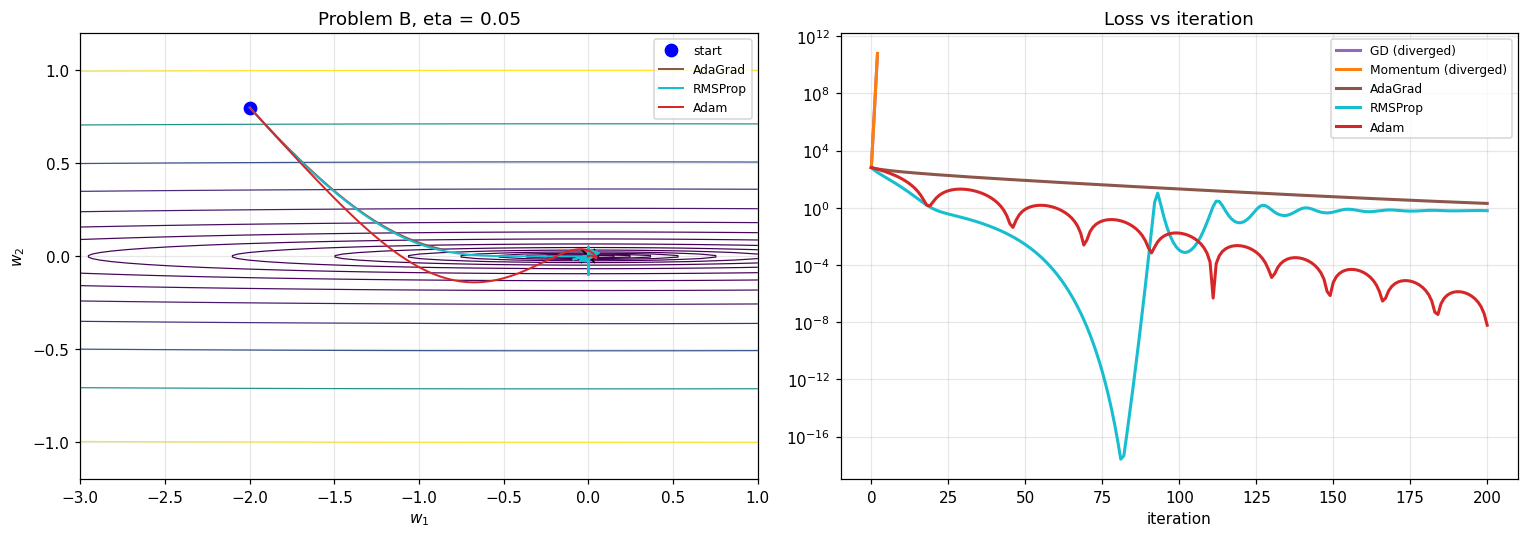

In [8]:
# Experiment 3a: problem B at a learning rate that is 50x GD's stability limit (2/lambda_max = 0.001).
LR = 0.05
N = 200

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
draw_contours(axes[0], prob_B, xlim=(-3, 1), ylim=(-1.2, 1.2))
axes[0].plot(*w0, "bo", ms=8, label="start")
for name, (_, color) in OPTIMISERS.items():
    path, loss = run(name, prob_B, LR, N)
    diverged = not np.isfinite(loss[-1])
    if not diverged:
        axes[0].plot(path[:, 0], path[:, 1], "-", color=color, lw=1.3, label=name)
    axes[1].semilogy(loss, color=color, lw=2, label=name + (" (diverged)" if diverged else ""))
    print(f"{name:9s} final L = {'diverged' if diverged else format(loss[-1], '.3e')}")
axes[0].set_title(f"Problem B, eta = {LR}"); axes[0].legend(fontsize=8)
axes[1].set_title("Loss vs iteration"); axes[1].set_xlabel("iteration"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to take from this**

- GD and Momentum diverge. Adam converges to about $10^{-8}$ with the *same* $\eta$. This is the per-coordinate rescaling at work: the steep $w_2$ direction (curvature 2000) and the flat $w_1$ direction (curvature 2) both get steps of size about $\eta$, instead of the steep direction forcing a tiny global step.
- AdaGrad and RMSProp don't converge at this particular $\eta$. For AdaGrad that is the "$\eta$ too small" regime from Experiment 2 (it needs $\eta\gtrsim0.2$), so this is not a fair verdict on AdaGrad. A shared $\eta$ is just one slice of the sweep.

## Experiment 3b: Problem C (rotated valley), each Optimiser at its Own Best $\eta$

Here a shared $\eta$ would be unfair, so each optimiser is run at the best learning rate from the sweep (judged by final loss at iteration 200). Adam and AdaGrad hit the top of the grid ($\eta=1$), so their true optimum may be higher.

GD        best eta = 0.0007   final L = 1.028e+00
Momentum  best eta = 0.0015   final L = 7.760e-06
AdaGrad   best eta = 1.0000   final L = 5.228e-01
RMSProp   best eta = 0.0147   final L = 5.072e-01
Adam      best eta = 1.0000   final L = 9.107e-02


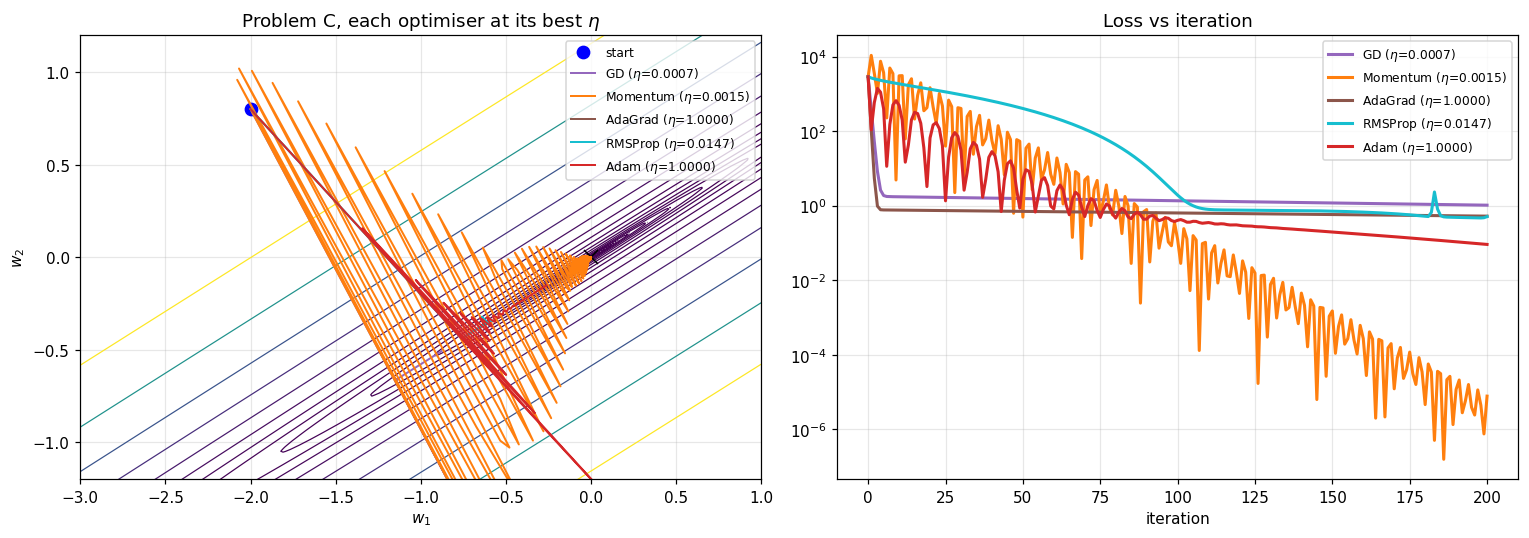

In [9]:
# Experiment 3b: problem C (rotated valley). A shared eta would be unfair here, so each optimiser
# gets ITS OWN best learning rate from the sweep above.
N = 200
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
draw_contours(axes[0], prob_C, xlim=(-3, 1), ylim=(-1.2, 1.2))
axes[0].plot(*w0, "bo", ms=8, label="start")

for name, (_, color) in OPTIMISERS.items():
    y = sweeps[prob_C["name"]][name]
    best_lr = lrs[np.nanargmin(y)]
    path, loss = run(name, prob_C, best_lr, N)
    axes[0].plot(path[:, 0], path[:, 1], "-", color=color, lw=1.3, label=f"{name} ($\\eta$={best_lr:.4f})")
    axes[1].semilogy(loss, color=color, lw=2, label=f"{name} ($\\eta$={best_lr:.4f})")
    print(f"{name:9s} best eta = {best_lr:.4f}   final L = {loss[-1]:.3e}")

axes[0].set_title("Problem C, each optimiser at its best $\\eta$"); axes[0].legend(fontsize=8)
axes[1].set_title("Loss vs iteration"); axes[1].set_xlabel("iteration"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to take from this**

- Adam's rescaling treats each *coordinate* separately. When the valley is rotated, the steep and flat directions are mixed across both coordinates, so rescaling axes cannot straighten the valley. Adam gets nowhere near the minimum in 200 steps (final $L\approx0.09$).
- Momentum, which does not care about axis alignment, reaches $\sim10^{-5}$, but look at its curve: it oscillates violently (the loss swings over many orders of magnitude) and the final value is where one swing happened to end up. "Best $\eta$ by final loss" can flatter an oscillating run, so treat this as an illustration, not a benchmark.
- Takeaway: Adam is a *diagonal* method. It helps with badly scaled coordinates and does little for ill-conditioning that is rotated relative to the axes.

## Experiment 4: Why bias correction matters?

Feed a constant gradient $g=1$. The correct moment estimates are then exactly $m=v=1$. Because $m_0=v_0=0$, the raw averages start far below 1 and take a long time to catch up (about $1/(1-\beta)$ steps: 10 for $m$, 1000 for $v$).

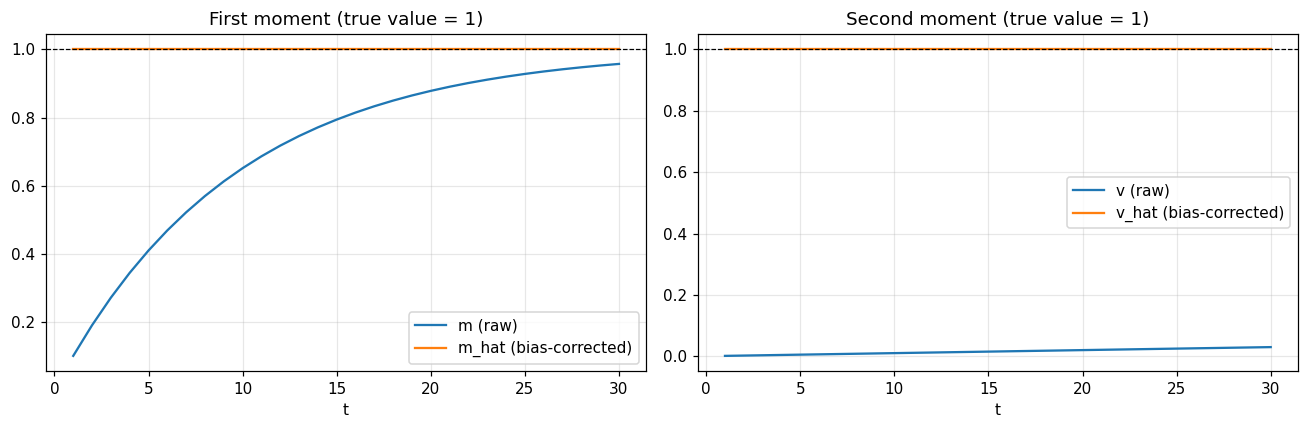

t = 1 : m = 0.1000  m_hat = 1.0000  |  v = 0.0010  v_hat = 1.0000
t = 30: m = 0.9576  m_hat = 1.0000  |  v = 0.0296  v_hat = 1.0000

First step size WITHOUT bias correction: 0.3162   WITH correction: 0.1000


In [10]:
# Experiment 4: why bias correction matters. Feed a CONSTANT gradient g = 1, so the correct m and v are both 1.
beta1, beta2 = 0.9, 0.999
T = 30
m = v = 0.0
rows = []
for t in range(1, T + 1):
    g = 1.0
    m = beta1 * m + (1 - beta1) * g
    v = beta2 * v + (1 - beta2) * g**2
    rows.append((t, m, m / (1 - beta1**t), v, v / (1 - beta2**t)))
rows = np.array(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(rows[:, 0], rows[:, 1], label="m (raw)")
axes[0].plot(rows[:, 0], rows[:, 2], label="m_hat (bias-corrected)")
axes[0].axhline(1, color="k", ls="--", lw=0.8)
axes[0].set_title("First moment (true value = 1)"); axes[0].set_xlabel("t"); axes[0].legend()
axes[1].plot(rows[:, 0], rows[:, 3], label="v (raw)")
axes[1].plot(rows[:, 0], rows[:, 4], label="v_hat (bias-corrected)")
axes[1].axhline(1, color="k", ls="--", lw=0.8)
axes[1].set_title("Second moment (true value = 1)"); axes[1].set_xlabel("t"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"t = 1 : m = {rows[0,1]:.4f}  m_hat = {rows[0,2]:.4f}  |  v = {rows[0,3]:.4f}  v_hat = {rows[0,4]:.4f}")
print(f"t = 30: m = {rows[-1,1]:.4f}  m_hat = {rows[-1,2]:.4f}  |  v = {rows[-1,3]:.4f}  v_hat = {rows[-1,4]:.4f}")

# Effect on the very first step (eta = 0.1, g = 1). The ideal step has size eta.
eta = 0.1
raw  = eta * rows[0, 1] / (np.sqrt(rows[0, 3]) + 1e-8)
corr = eta * rows[0, 2] / (np.sqrt(rows[0, 4]) + 1e-8)
print(f"\nFirst step size WITHOUT bias correction: {raw:.4f}   WITH correction: {corr:.4f}")

**What to take from this**

- At $t=1$ the raw $m$ is $0.1$ and the raw $v$ is $0.001$: both badly underestimate the truth. Dividing by $1-\beta^t$ recovers exactly 1 at every step.
- The *net* effect on the first step is not "too small". Because $v$ is underestimated much more than $m$ (the denominator is a square root), the uncorrected first step is $\eta\cdot0.1/\sqrt{0.001}\approx3.2\,\eta$, about **three times too large**. Bias correction brings it back to $\eta$.
- The correction factors $1/(1-\beta^t)\to1$, so it matters only for the first few steps ($m$) or first few hundred ($v$).

## Conclusion

| Observation (from the runs above) | Evidence |
|---|---|
| Adam tolerates a very wide range of $\eta$ | Converges for 11 of 25 rates on A and B (Exp. 2) |
| Adam works where GD/Momentum diverge on badly scaled axes | Problem B at $\eta=0.05$ (Exp. 3a) |
| Adam is not the fastest on an easy, well-scaled problem | Problem A (Exp. 1) |
| Adam's rescaling is per-coordinate, so a rotated valley is not fixed | Problem C (Exp. 3b) |
| Bias correction fixes a roughly 3× over-large first step | Exp. 4 |
| AdaGrad does very well on these deterministic quadratics at large $\eta$ | Exp. 2 |

**Limitations of this study:** Two-dimensional quadratics, exact (noise-free) gradients, one starting point, a 25-point learning-rate grid, and 100–200 iterations. It says nothing directly about stochastic mini-batch training, non-convex losses or neural networks, where Adam's practical reputation comes from. What it does show clearly is the mechanism behind Adam's robustness to the learning rate, and the situations where that mechanism stops helping.